# 04 · Why VIIRS sees more fire: a pixel by pixel check

> **What and why**
>
> - VIIRS records about six times more hotspots than MODIS. Here we look at why, pixel by pixel.
> - On 10 test tiles for all of 2019, we place every Suomi NPP 375 m hotspot on the 1 km MODIS grid and ask: did MODIS see it too?
> - Aqua passes at the same hours as Suomi NPP (about 13:30 and 01:30), so it is the fair comparison. Terra passes three hours earlier.
> - We split the answer by fire strength (FRP), day and night, and cloud. This physics is what the exchange rate in the model has to learn.

In [1]:
import sys, os
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO)); sys.path.insert(0, str(REPO / 'style'))
import pandas as pd, numpy as np, duckdb, matplotlib.pyplot as plt
import fireharmony_style as fh
from fireharmony import config as C, features as FE
fh.use(); pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = REPO / 'report' / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
con = C.connect()
from fireharmony import physics as PH
pts = pd.read_parquet(PH.out('viirs_points_2019.parquet'))
print(f"{len(pts):,} Suomi NPP hotspots on the 10 tiles in 2019")

4,113,015 Suomi NPP hotspots on the 10 tiles in 2019


## 1. The tiles

Each MODIS tile is about 1,100 by 1,100 km. Where they are, and how many VIIRS hotspots each one had.

In [2]:
tiles = pts.groupby('tile').agg(points=('frp', 'size'), lat=('lat', 'median'), lon=('lon', 'median'),
                                 weak_share=('frp', lambda f: (f < 5).mean()), clear_share=('aqua_view', lambda v: (v == 0).mean()))
tiles.round(3)

,points,lat,lon,weak_share,clear_share
tile,,,,,
h08v05,44382,34.531,-116.149,0.549,0.991
h11v03,75512,57.964,-116.978,0.547,0.970
h12v10,479387,-16.382,-58.845,0.472,0.947
h12v11,271304,-24.275,-58.255,0.449,0.989
h20v08,850193,6.660,25.220,0.456,0.969
h20v10,1279929,-13.626,25.501,0.402,0.991
h22v02,399479,62.852,104.604,0.570,0.991
h25v06,226290,23.693,82.349,0.731,0.991
h29v09,189113,-2.784,114.009,0.538,0.963


## 2. How often MODIS sees a VIIRS fire

Only hotspots where the MODIS cell had a clear view that day count here (no cloud, no missing data).

In [3]:
rows = []
for sat in ('aqua', 'terra'):
    clear = pts[pts[f'{sat}_view'] == 0]
    for dn, g in clear.groupby('daynight'):
        rows.append({'MODIS': sat.title(), 'pass': {'D': 'day', 'N': 'night'}[dn], 'VIIRS hotspots': len(g), 'share seen by MODIS': g[f'{sat}_seen'].mean()})
pd.DataFrame(rows).set_index(['MODIS', 'pass']).round(3)

VIIRS hotspots  share seen by MODIS
MODIS pass                                      
Aqua  day           2998597                0.440
      night         1029243                0.459
Terra day           2921961                0.250
      night         1023654                0.498

## 3. The detection curve

The chance that Aqua sees a VIIRS fire, by the fire radiative power (FRP) that VIIRS measured. Strong fires are almost always seen; weak fires mostly are not. The weakest group (below 1 MW) comes out a little higher than the next one: weak hotspots at the edge of a big fire count as seen when MODIS sees the big fire in the next cell.

{'aqua D': 10.096167720576194, 'aqua N': 2.045942255498535, 'terra D': None, 'terra N': 1.6228294696377996}


,aqua D,aqua N,terra D,terra N
bin,,,,
0.7,0.268,0.259,0.151,0.267
1.4,0.163,0.409,0.092,0.462
2.4,0.221,0.538,0.134,0.601
3.9,0.316,0.644,0.192,0.692
5.9,0.402,0.717,0.242,0.741
8.4,0.466,0.763,0.272,0.763
12.0,0.532,0.818,0.295,0.788
17.0,0.592,0.852,0.318,0.789
24.0,0.641,0.868,0.331,0.814


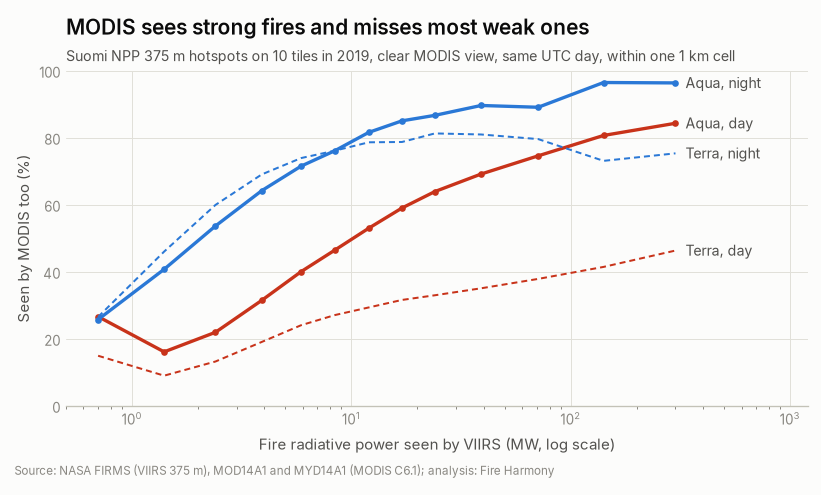

In [4]:
bins = [0, 1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100, 200, 1e6]
mid = [0.7, 1.4, 2.4, 3.9, 5.9, 8.4, 12, 17, 24, 39, 71, 141, 300]
fig, ax = plt.subplots(figsize=fh.SIZE['full'])
curves = {}
for sat, dash in (('aqua', None), ('terra', (0, (3, 2)))):
    clear = pts[pts[f'{sat}_view'] == 0].copy()
    clear['bin'] = pd.cut(clear.frp, bins, right=False, labels=mid)
    for dn, col in (('D', fh.EMBER[5]), ('N', fh.SENSOR['MODIS'])):
        g = clear[clear.daynight == dn].groupby('bin', observed=True)[f'{sat}_seen'].agg(['mean', 'size'])
        g = g[g['size'] >= 200]
        curves[(sat, dn)] = g
        x = np.array(g.index, dtype=float)
        ax.plot(x, 100 * g['mean'], color=col, lw=2 if sat == 'aqua' else 1.2, ls=dash if dash else '-', marker='o' if sat == 'aqua' else None, ms=3)
        fh.direct_label(ax, x[-1], 100 * g['mean'].iloc[-1], f"{sat.title()}, {'day' if dn == 'D' else 'night'}")
ax.set_xscale('log'); ax.set_ylim(0, 100); ax.set_xlim(0.5, 1200)
ax.set_xlabel('Fire radiative power seen by VIIRS (MW, log scale)'); ax.set_ylabel('Seen by MODIS too (%)')
fh.clean(ax, grid_axis='both')
fh.title(ax, 'MODIS sees strong fires and misses most weak ones', 'Suomi NPP 375 m hotspots on 10 tiles in 2019, clear MODIS view, same UTC day, within one 1 km cell')
fh.source(fig, 'Source: NASA FIRMS (VIIRS 375 m), MOD14A1 and MYD14A1 (MODIS C6.1); analysis: Fire Harmony')
fh.save(fig, FIG / 'fig19_modis_detection_curve')
def half_point(g):
    x, y = np.log(np.array(g.index, dtype=float)), g['mean'].to_numpy()
    k = np.argmax(y >= 0.5)
    return float(np.exp(np.interp(0.5, y[k - 1:k + 1], x[k - 1:k + 1]))) if y.max() >= 0.5 and k > 0 else None
print({f'{s} {d}': half_point(g) for (s, d), g in curves.items()})
pd.DataFrame({f'{s} {d}': g['mean'] for (s, d), g in curves.items()}).round(3)

## 4. Cloud

MODIS cannot see a fire through cloud. How often was the MODIS cell cloudy, or had no data, when VIIRS saw a fire?

In [5]:
v = pts.aqua_view.map({0: 'clear', 1: 'cloud', 2: 'no data', -1: 'no file'}).value_counts(normalize=True)
v.round(3).rename('share of VIIRS hotspots (Aqua cell)').to_frame()

,share of VIIRS hotspots (Aqua cell)
aqua_view,
clear,0.979
cloud,0.014
no data,0.007


## 5. What this means for the exchange rate

Tiles with many weak fires need a bigger exchange rate: for every hotspot Aqua sees, VIIRS sees more.

In [6]:
t = pts[pts.aqua_view == 0].groupby('tile').agg(weak_share=('frp', lambda f: (f < 5).mean()), seen=('aqua_seen', 'mean'), n=('frp', 'size'))
t['VIIRS per hotspot Aqua sees'] = 1 / t.seen
print(f"correlation of weak share with the exchange rate across tiles: {t.weak_share.corr(t['VIIRS per hotspot Aqua sees']):.2f}")
t.sort_values('weak_share').round(3)

correlation of weak share with the exchange rate across tiles: 0.65


,weak_share,seen,n,VIIRS per hotspot Aqua sees
tile,,,,
h20v10,0.402,0.384,1268628,2.605
h12v11,0.448,0.476,268249,2.102
h20v08,0.456,0.346,823992,2.890
h30v10,0.472,0.535,293287,1.870
h12v10,0.472,0.552,454164,1.811
h29v09,0.537,0.406,182109,2.463
h11v03,0.546,0.665,73251,1.505
h08v05,0.548,0.439,43989,2.276
h22v02,0.572,0.776,395947,1.288


> **Key findings**
>
> - On a clear day, Aqua MODIS sees 44% of the fires that Suomi NPP VIIRS sees at the same hour (46% at night). Terra, three hours earlier, sees only 25% by day.
> - Strong fires are almost always seen: above 100 MW, Aqua sees 81 to 85% of them by day and 97% at night. Weak fires are mostly missed: by day the chance reaches one in two only at about 10 MW.
> - At night MODIS sees weak fires much better (half of them at about 2 MW), because the cool ground makes a small fire stand out.
> - Cloud is a small part of the story: the Aqua cell was cloudy for only 1.4% of VIIRS fires, because both satellites look at the same sky.
> - Where more fires are weak, the exchange rate is higher (r = 0.65 across the 10 tiles). In central India, where 73% of VIIRS fires are below 5 MW, VIIRS records 6.5 fires for every one Aqua sees. In Siberia it is 1.3.
> - The rest of the six times gap is pixel size: one MODIS 1 km pixel covers about seven VIIRS 375 m pixels, so one fire can give several VIIRS hotspots. This is why the model uses how many small cells MODIS saw burning, and not only the count.